# Validate against onshore buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/<Case>_observations.json`
4. Processed hourly buoy files in `inputs/Observations/processed/` (notebook 03,
   `utils/buoy_archive.py`).

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically — this case's buoys are all
Rijkswaterstaat Waterinfo/DDL exports (`Hm0`/`Th0`/`Tm-10`), which only give
usable `hs`/`dir` (see `utils/rijkswaterstaat.py`: `Tm-10` is a
spectral mean period, not the peak period `tp` the metamodel predicts, so it's
dropped rather than mislabeled — `tp`/`spr` are simply not scored against
buoys here).

This case has a single (nearshore) buoy network, so the separate
`10a_Validate_Offshore_Buoys.ipynb` template was dropped — this notebook
covers all 9 configured buoys.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils import simulation as sim
from utils import validation as val
from utils.config import resolve

## Configuration

Every buoy in the observations GeoJSON (`instrument_id` keys, notebook 03). SnapWave
site labels are `buoy_{instrument_id}`. Processed hourly files (`hs`, `tp`, `dir`,
`spr` where measured) come from `utils/buoy_archive.py` (Waterinfo + CMEMS + the
earlier Rijkswaterstaat exports), built in notebook 03.

In [7]:
period = slice("2013-01-01", "2013-05-09")  # matches the 09/reconstruction cache span
offshore_name = "WHACS"
mda_n = 550  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set (metamodel.sets) fitted on the buoys
pca_variance = 0.99

# Every buoy of the observations GeoJSON (notebook 03); processed hourly files
# (hs, tp, dir, spr) in inputs/Observations/processed/<instrument_id>.nc
sites = ["buoy_EierlandseGat"]  # obs.list_snapwave_buoy_sites()
buoy_instruments = [obs.instrument_id(s) for s in sites]

requested_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    sim.cases_dir("dynamic") / f"Dynamic_Cases_{offshore_name}_2013_0101_0509.nc"
)

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"mda_n          : {mda_n}")
print(f"metamodel      : {mm_set}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")
print(f"dynamic path   : {dynamic_path}")
print(f"dynamic exists : {dynamic_path.is_file()}")

Observations JSON: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
period         : slice('2013-01-01', '2013-05-09', None)
mda_n          : 550
metamodel      : buoys
sites          : ['buoy_EierlandseGat']
requested vars : ['hs', 'tp', 'dir', 'spr']
dynamic path   : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SWAN_CASES_Dynamic/Dynamic_Cases_WHACS_2013_0101_0509.nc
dynamic exists : True


## 1 · Check models

In [8]:
mm.require_models_all(mm_set, mda_n, pca_variance=pca_variance)

## 2 · Buoy observations

**2a.** The processed hourly file of each buoy (built in notebook 03 by
`utils/buoy_archive.py`), with its number of valid `hs` hours in `period`.

**2b.** Load each processed file, slice to `period`, and build a validation dataset
on `(time, sites)` with CF-style attributes. Site metadata (lon/lat/depth) comes
from the observations GeoJSON.

In [9]:
processed_dir = resolve("inputs/Observations/processed")

# Processed observation NetCDF per SnapWave site id (notebook 03)
buoy_raw_files: dict[str, Path] = {}
for instrument_id in buoy_instruments:
    site_id = obs.snapwave_site_id(instrument_id)
    buoy_raw_files[site_id] = processed_dir / f"{instrument_id}.nc"
    with xr.open_dataset(buoy_raw_files[site_id]) as check:
        n_valid = int(check["hs"].sel(time=period).notnull().sum())
    print(f"{site_id}: {n_valid} valid hourly hs in {period}")

buoy_EierlandseGat: 3086 valid hourly hs in slice('2013-01-01', '2013-05-09', None)


In [10]:
# CF-style attributes for validation plots
_BUOY_VAR_ATTRS = {
    "hs": {"standard_name": "sea_surface_wave_significant_height", "units": "m"},
    "tp": {"standard_name": "sea_surface_wave_period", "units": "s"},
    "dir": {"standard_name": "sea_surface_wave_from_direction", "units": "degree"},
    "spr": {
        "standard_name": "sea_surface_wave_directional_spread",
        "units": "degree",
    },
}

chunks: list[xr.Dataset] = []
for site_id in sites:
    raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)

    if "Efth" in raw or "efth" in raw:
        spec_name = "Efth" if "Efth" in raw else "efth"
        stats = raw[spec_name].spec.stats(["hs", "tp", "dm", "dspr"]).load()
        site_ds = stats.rename({"dm": "dir", "dspr": "spr"})
    else:
        rename = {}
        if "dspr" in raw.data_vars and "spr" not in raw.data_vars:
            rename["dspr"] = "spr"
        if rename:
            raw = raw.rename(rename)
        vars_out = {}
        for name in requested_variables:
            if name in raw.data_vars:
                vars_out[name] = raw[name]
            elif name == "dir" and "dm" in raw.data_vars:
                vars_out["dir"] = raw["dm"]
        if "hs" not in vars_out:
            raise ValueError(f"{site_id}: processed buoy file must contain hs or Efth")
        site_ds = xr.Dataset(vars_out)

    site_ds = site_ds.expand_dims(sites=[site_id]).transpose("time", "sites")
    for var, attrs in _BUOY_VAR_ATTRS.items():
        if var in site_ds:
            site_ds[var].attrs.update(attrs)
    chunks.append(obs.attach_buoy_site_meta(site_ds, site_id))

buoy = xr.concat(chunks, dim="sites") if len(chunks) > 1 else chunks[0]
buoy

<xarray.Dataset> Size: 124kB
Dimensions:         (sites: 1, time: 3086)
Coordinates:
  * sites           (sites) object 8B 'buoy_EierlandseGat'
    site_source     (sites) <U4 16B 'buoy'
    site_label      (sites) <U13 52B 'EierlandseGat'
    site_longitude  (sites) float64 8B 4.66
    site_latitude   (sites) float64 8B 53.28
    site_depth      (sites) float64 8B 27.0
  * time            (time) datetime64[ns] 25kB 2013-01-01 ... 2013-05-09T23:0...
Data variables:
    hs              (time, sites) float64 25kB 1.682 1.642 1.484 ... 1.46 1.511
    tp              (time, sites) float64 25kB 8.66 7.99 7.587 ... 6.397 6.984
    dir             (time, sites) float64 25kB 234.8 238.7 244.0 ... 227.0 224.1
    spr             (time, sites) float64 25kB 35.0 31.8 32.0 ... 30.33 28.67

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in the case JSON —
currently WHACS only).

In [11]:
timings: dict[str, float] = {}

t0 = time.perf_counter()
bulk = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,
)
bulk_wind = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,
    wind_correction=True,
)
timings["Bulk metamodel"] = time.perf_counter() - t0

t0 = time.perf_counter()
spectral = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,
)
spectral_wind = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,
    wind_correction=True,
)
timings["Spectral metamodel"] = time.perf_counter() - t0

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites, metamodel=mm_set)
dynamic = dynamic.sel(sites=site_ids).load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=requested_variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk,
    "Bulk metamodel (wind-corrected)": bulk_wind,
    "Spectral metamodel": spectral,
    "Spectral metamodel (wind-corrected)": spectral_wind,
    val.DYNAMIC_REFERENCE_LABEL: dynamic,
}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

Comparing: ['hs', 'tp', 'dir', 'spr']


## 4 · Metrics vs buoy

In [12]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
    pca_variance=pca_variance,
)

summary = val.metrics_summary(results)
summary

,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label,model
0,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,hs,Hs,3086,0.120275,0.269203,0.208630,0.164137,0.944239,0.851506,Buoy,WHACS (closest goal),WHACS (closest goal)
1,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,tp,Tp,3084,0.250918,1.676365,0.245132,0.232959,0.700099,0.270989,Buoy,WHACS (closest goal),WHACS (closest goal)
2,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,dir,Dir,3086,9.150800,23.575252,NaN,NaN,NaN,0.873751,Buoy,WHACS (closest goal),WHACS (closest goal)
3,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,spr,Spr,2882,-5.157183,10.149019,0.256332,0.213184,0.651266,0.093063,Buoy,WHACS (closest goal),WHACS (closest goal)
4,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,hs,Hs,3086,0.110008,0.302263,0.234252,0.191871,0.930951,0.812793,Buoy,ERA5 (closest goal),ERA5 (closest goal)
5,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,tp,Tp,3084,-0.124477,1.489532,0.217811,0.208622,0.706544,0.424432,Buoy,ERA5 (closest goal),ERA5 (closest goal)
6,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,dir,Dir,3086,11.999552,30.187993,NaN,NaN,NaN,0.792994,Buoy,ERA5 (closest goal),ERA5 (closest goal)
7,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,spr,Spr,2882,-8.259945,11.526125,0.291113,0.196060,0.699711,-0.169758,Buoy,ERA5 (closest goal),ERA5 (closest goal)
8,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,hs,Hs,3086,-0.330147,0.507170,0.393053,0.262384,0.843828,0.472941,Buoy,Bulk metamodel,Bulk metamodel
9,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",buoy_EierlandseGat,buoy,waves,tp,Tp,3082,0.088605,1.776367,0.259852,0.249463,0.646461,0.179795,Buoy,Bulk metamodel,Bulk metamodel


## 4b · Save summary

In [13]:
# `period` is a slice here (not a single string) — derive a clean,
# filesystem-safe label from it once; the summary PNG save cell reuses it.
period_label = period if isinstance(period, str) else f"{period.start}-{period.stop}"

summary_out = summary.copy()
summary_out.insert(0, "period", period_label)
summary_out.insert(1, "metamodel", mm_set)
summary_out.insert(2, "mda_candidate", mda_n)
summary_out.insert(3, "offshore_name", offshore_name)
summary_out["reconstruct_seconds"] = summary_out["model"].map(timings)

out_path = val.buoy_validation_path("onshore", period_label)
out_path.parent.mkdir(parents=True, exist_ok=True)
summary_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/onshore_summary_2013-01-01-2013-05-09.csv


## 5 · Scatter plots

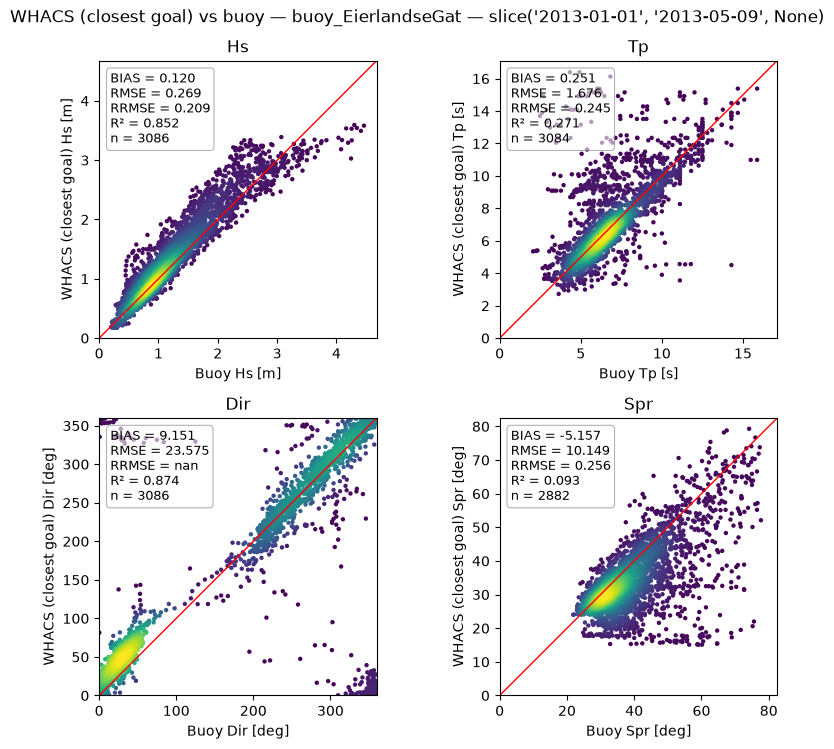

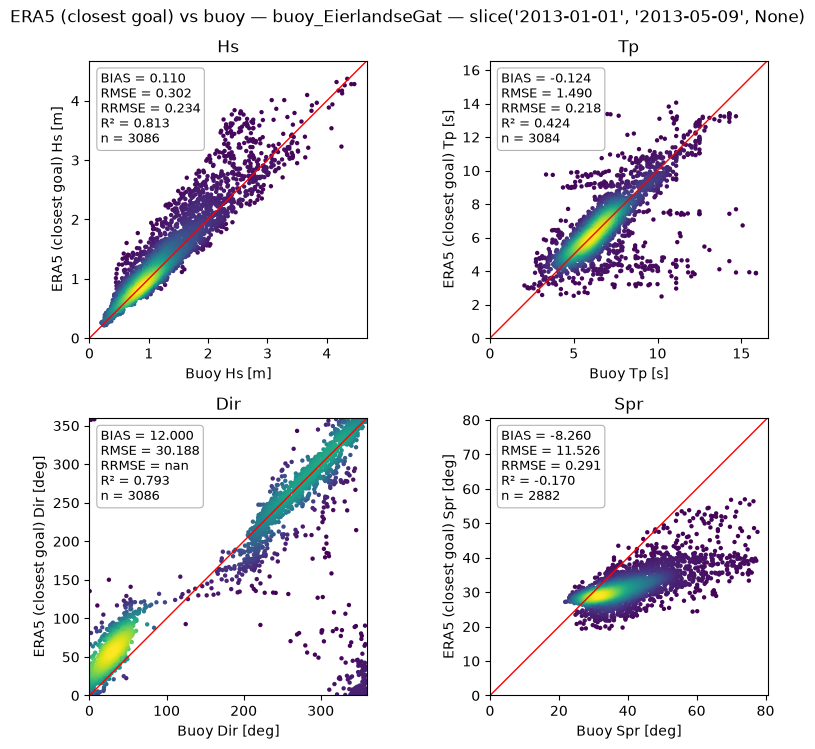

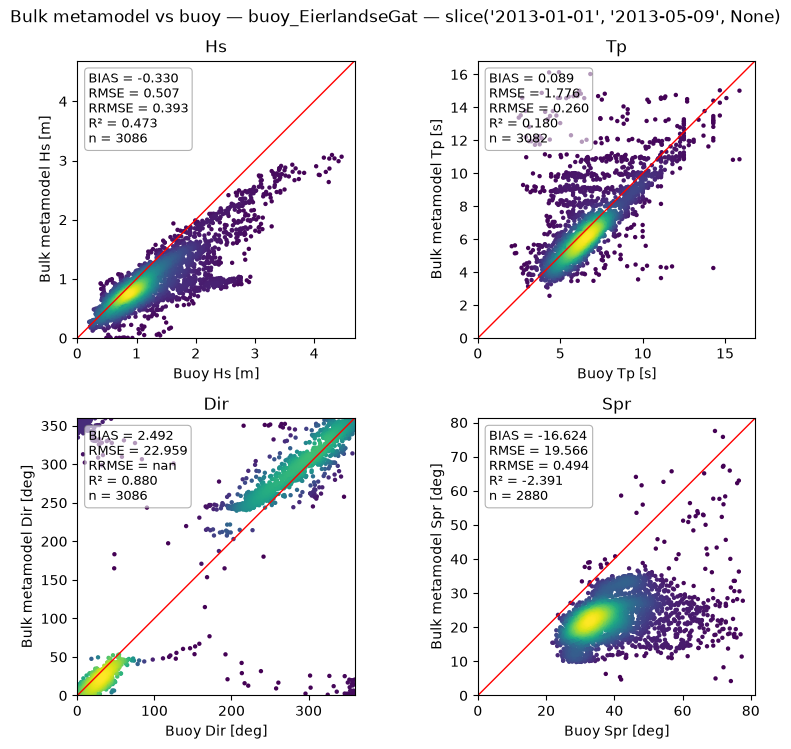

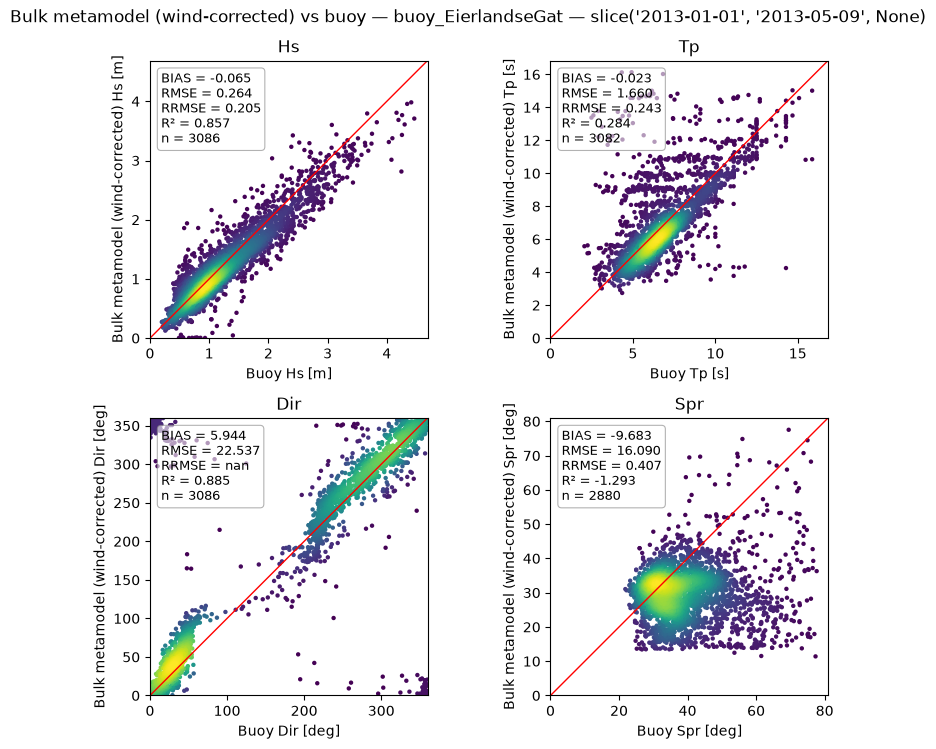

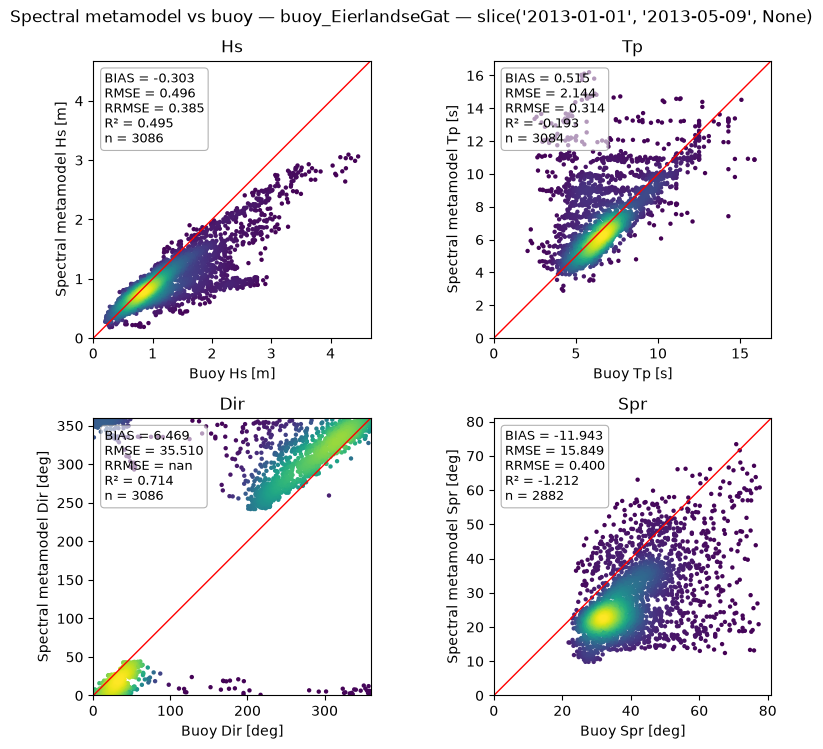

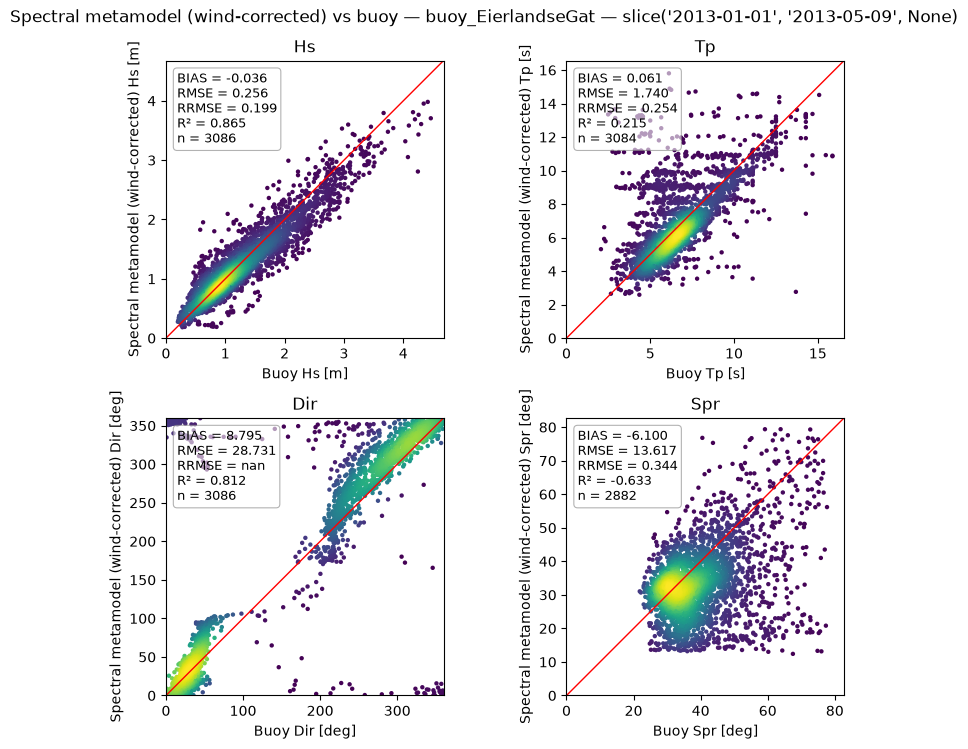

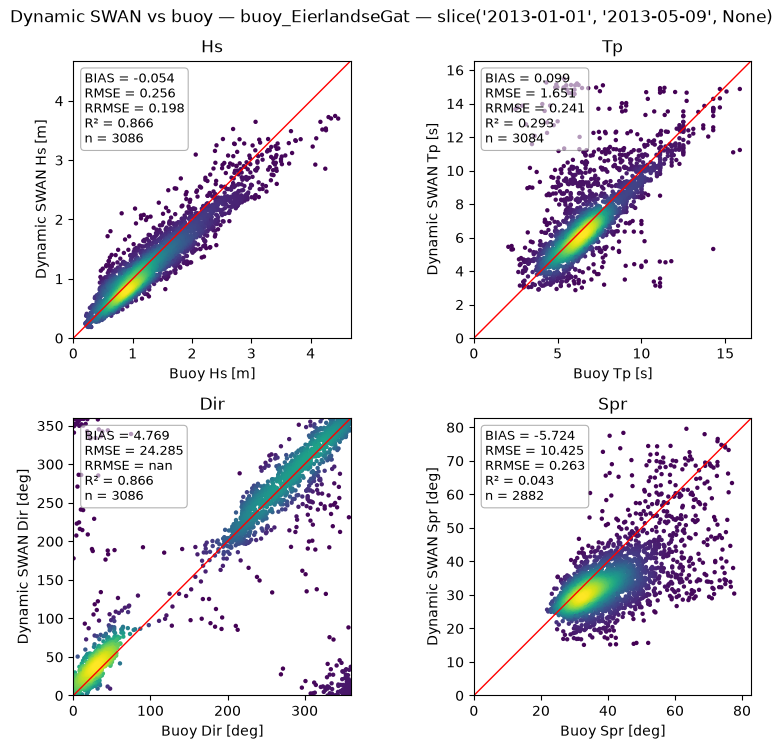

In [14]:
for site in sites:
    for name, result in results.items():
        result.plot_scatter(
            site,
            variables=variables,
            estimate_label=name,
            reference_label="Buoy",
        )
        plt.suptitle(f"{name} vs buoy — {site} — {period}")
        plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

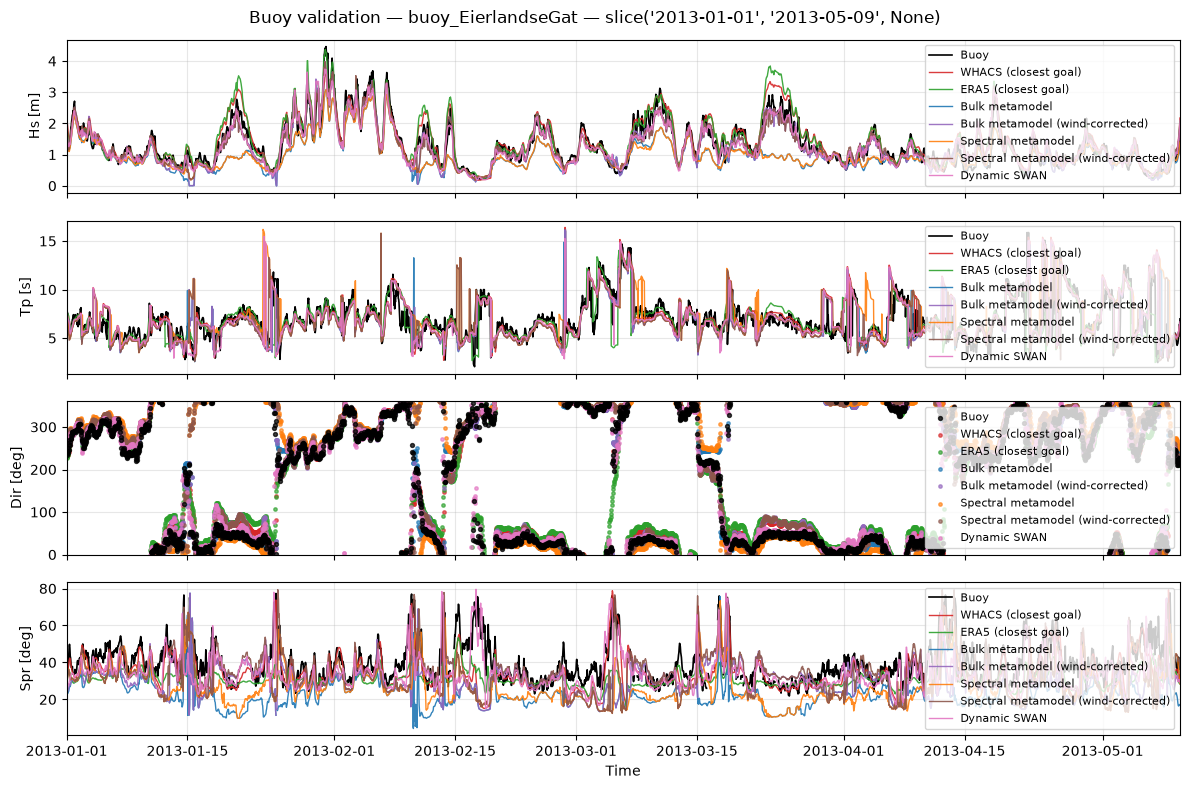

In [15]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()

## 7 · Save per-buoy summary PNG (GUI)

Density scatter (top row, buoy vs. spectral metamodel) + one wide Hs/Tp time series (bottom row, cropped to when the buoy actually has data) — one combined PNG per buoy, shown as-is in the GUI's Buoy Validation tab when you click that buoy's star on the map.

In [19]:
for site in sites:
    fig = val.plot_buoy_summary(
        buoy,
        estimates,
        site,
        variables=variables,
        reference_label="Buoy",
        period_label=period_label,
        estimate_label="Spectral metamodel (wind-corrected)",
    )
    out_path = val.buoy_summary_figure_path(site)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"saved {out_path}")

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_EierlandseGat.png
